In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import matplotlib.patches as patches
import matplotlib.cm as cm
import matplotlib.colors as mcolors

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
STEP_SIZE = 20

In [3]:
def discrete_mutation(individual, num_types, mutation_rate=0.1):
    mutated = individual.copy()
    for i in range(len(mutated)):
        if np.random.rand() < mutation_rate:
            mutated[i] = np.random.randint(0, num_types)
    return mutated

def gaussian_mutation(individual, sigma=0.1):
    noise = np.random.normal(0, sigma, size=len(individual))
    return individual + noise

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [4]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [5]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, num_types, pop_size=100, chromosome_length=100, crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.chromosome_length = chromosome_length
        self.num_types = num_types

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie kolejności prostokątów
        self.population = np.random.randint(0, num_types, size=(pop_size, chromosome_length))

        self.reset_population()

    def reset_population(self):
        self.population = np.random.randint(0, self.num_types, size=(self.pop_size, self.chromosome_length))
        
    def train(self, generations=1000, pbar=None):
        if pbar is None:
            scores = np.array([self.objective_func(ind) for ind in tqdm(self.population, desc="Inicjalizacja")])
            iterator = tqdm(range(generations), desc="Ewolucja")
        else:
            scores = np.array([self.objective_func(ind) for ind in self.population])
            iterator = range(generations)

        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in iterator:
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())

            if pbar is not None:
                pbar.update(1)
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [6]:
def create_circle_mask(radius):
    size = 2 * radius
    board = np.ones((size, size), dtype=np.int8)
    
    cx, cy = radius, radius
    y, x = np.ogrid[:size, :size]
    inside_circle = (x - cx)**2 + (y - cy)**2 <= radius**2
    board[inside_circle] = 0
    
    return board

In [7]:
def cutting_stock_fitness(individual, radius, rectangles_pool, step=STEP_SIZE):
    board = create_circle_mask(radius)
    size = 2 * radius
    total_value = 0
    
    for rect_id in individual:
        w = int(rectangles_pool.iloc[rect_id]['width'])
        h = int(rectangles_pool.iloc[rect_id]['height'])
        val = rectangles_pool.iloc[rect_id]['value']
        
        placed = False
        
        for y in range(0, size - h + 1, step):
            for x in range(0, size - w + 1, step):
                
                if (board[y, x] == 0 and 
                    board[y + h - 1, x] == 0 and 
                    board[y, x + w - 1] == 0 and 
                    board[y + h - 1, x + w - 1] == 0):
                    
                    window = board[y:y+h, x:x+w]
                    
                    if not np.any(window):
                        board[y:y+h, x:x+w] = 1
                        total_value += val
                        placed = True
                        break
            
            if placed:
                break
                
    return -total_value

In [8]:
def train_N(ea, generations, N=10):
    summary_results = []
    scores = []
    
    total_steps = N * generations
    
    with tqdm(total=total_steps, desc=f"Testy: {N}x{generations} gen") as pbar:
        for i in range(N):
            ea.reset_population()
            
            _, best_score, _, _ = ea.train(generations=generations, pbar=pbar)        
            
            true_score = -best_score
            scores.append(true_score)
            
            pbar.set_postfix({'Ukończono test': f"{i+1}/{N}", 'Ostatni wynik': f"{true_score}"})
            
    summary_results.append({
        'Mean Score': np.mean(scores),
        'Std Dev': np.std(scores),
        'Min': np.min(scores),
        'Max': np.max(scores)
    })
    
    results_df = pd.DataFrame(summary_results)
    return results_df.sort_values(by='Mean Score').reset_index(drop=True), scores

In [9]:
def create_summary_dataframe(df_dict):
    all_dfs = []
    
    for radius, df in df_dict.items():
        temp_df = df.copy()
        
        temp_df.insert(0, 'R', radius)
        
        all_dfs.append(temp_df)
        
    final_df = pd.concat(all_dfs, ignore_index=True)
    
    final_df = final_df.round(2)
    
    return final_df

In [10]:
def plot_radii_boxplots(scores_dict, thresholds_dict=None):
    radii = list(scores_dict.keys()) 
    labels = [f"R = {radius}" for radius in radii]
    data = list(scores_dict.values())
    
    fig, ax = plt.subplots(figsize=(10, 6))

    box = ax.boxplot(data, labels=labels, patch_artist=True, zorder=3)
    
    for patch in box['boxes']:
        patch.set_facecolor('lightblue')
        
    for median in box['medians']:
        median.set_color('black')
            
    if thresholds_dict is not None:
        for x_pos, radius in enumerate(radii, start=1):
            if radius in thresholds_dict:
                y_val = thresholds_dict[radius]
                label = 'Threshold' if x_pos == 1 else ""
                ax.plot(x_pos, y_val, 'ro', markersize=10, zorder=4, label=label)
        
        ax.legend(loc='best', fontsize=12)
                
    ax.set_title("Rozkład wyników upakowania dla różnych promieni koła", fontsize=16, pad=15)
    ax.set_xlabel("Promień koła", fontsize=14)
    ax.set_ylabel("Uzyskana wartość", fontsize=14)
    
    ax.yaxis.grid(True, linestyle='--', alpha=0.7, zorder=0)

    plt.tight_layout()
    plt.show()

# R=800

In [11]:
r = pd.read_csv("cutting/r800.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 800
num_types = len(rectangles_pool)

In [12]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_800 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=100,
    crossover_prob=0.9,
    mutation_prob=0.5
)

results_800, scores_800 = train_N(ea_800, 30, 3)

Testy: 3x30 gen: 100%|██████████| 90/90 [35:31<00:00, 23.68s/it, Ukończono test=3/3, Ostatni wynik=24980]


# R=850

In [13]:
r = pd.read_csv("cutting/r850.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 850
num_types = len(rectangles_pool)

In [14]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_850 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=200,
    crossover_prob=0.9,
    mutation_prob=0.5
)

results_850, scores_850 = train_N(ea_850, 10, 3)

Testy: 3x10 gen: 100%|██████████| 30/30 [17:20<00:00, 34.68s/it, Ukończono test=3/3, Ostatni wynik=432460]


# R=1000

In [15]:
r = pd.read_csv("cutting/r1000.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1000
num_types = len(rectangles_pool)

In [16]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1000 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=120,
    crossover_prob=0.9,
    mutation_prob=0.5
)

results_1000, scores_1000 = train_N(ea_1000, 10, 3)

Testy: 3x10 gen: 100%|██████████| 30/30 [15:40<00:00, 31.36s/it, Ukończono test=3/3, Ostatni wynik=27300]


# R=1100

In [17]:
r = pd.read_csv("cutting/r1100.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1100
num_types = len(rectangles_pool)

In [18]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1100 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=120,
    crossover_prob=0.9,
    mutation_prob=0.5
)

results_1100, scores_1100 = train_N(ea_1100, 10, 3)

Testy: 3x10 gen: 100%|██████████| 30/30 [18:59<00:00, 37.99s/it, Ukończono test=3/3, Ostatni wynik=31580]


# R=1200

In [19]:
r = pd.read_csv("cutting/r1200.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1200
num_types = len(rectangles_pool)

In [20]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1200 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=160,
    crossover_prob=0.9,
    mutation_prob=0.5
)

results_1200, scores_1200 = train_N(ea_1200, 10, 3)

Testy: 3x10 gen: 100%|██████████| 30/30 [27:20<00:00, 54.68s/it, Ukończono test=3/3, Ostatni wynik=39680]


# Podsumowanie

In [21]:
wyniki_df = {
    800: results_800,
    850: results_850,
    1000: results_1000,
    1100: results_1100,
    1200: results_1200
}

wyniki_scores = {
    800: scores_800,
    #850: scores_850,
    1000: scores_1000,
    1100: scores_1100,
    1200: scores_1200
}

thresholds = {
    800: 30000,
    1000: 17500,
    1100: 25000,
    1200: 30000
}

tabela_podsumowujaca = create_summary_dataframe(wyniki_df)
tabela_podsumowujaca

,R,Mean Score,Std Dev,Min,Max
0,800,25066.67,388.62,24640,25580
1,850,440120.00,5435.02,432460,444500
2,1000,27500.00,588.78,26900,28300
3,1100,30420.00,860.85,29520,31580
4,1200,39506.67,204.18,39220,39680


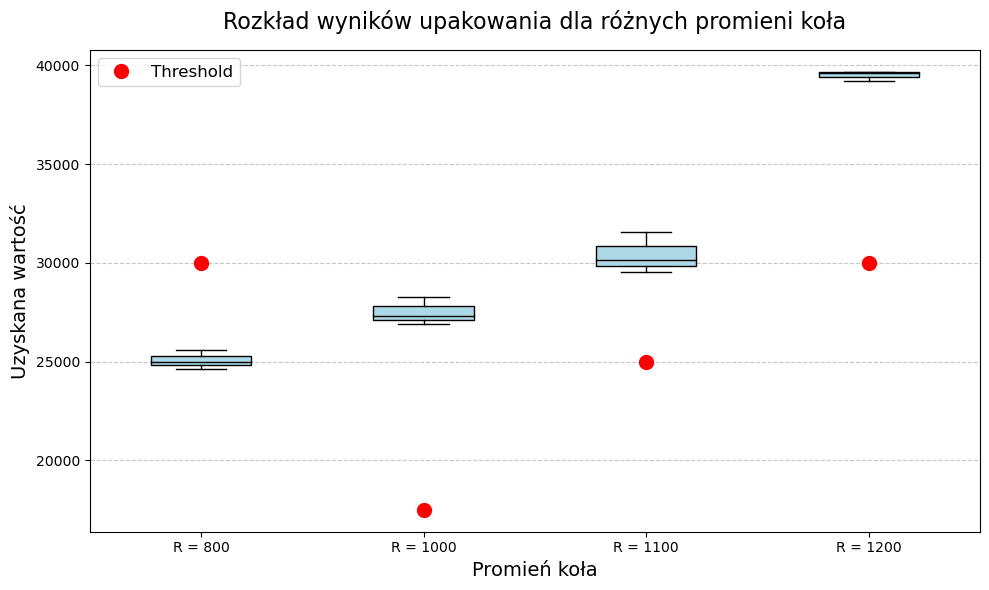

In [22]:
plot_radii_boxplots(wyniki_scores, thresholds)